In [16]:
from pathlib import Path
import cv2, os
from collections import defaultdict
import numpy as np

In [17]:
%run 00_utils.ipynb

Root-Verzeichnis: /home/jessh/Study/Bachelor-Thesis


In [18]:
def find_text_in_seq(root_dir):
    global ROOT_DIR
    east_weights_pth = ROOT_DIR / "weights" / "EAST" / "frozen_east_text_detection.pb"
    all_dirs_set = set()

    conf_thresh = 0.55
    nms_thresh  = 0.4
    scale = 1.0

    textDetectorEAST= cv2.dnn_TextDetectionModel_EAST(str(east_weights_pth))
    textDetectorEAST.setConfidenceThreshold(conf_thresh)
    textDetectorEAST.setNMSThreshold(nms_thresh)

    paths = get_all_dir_names(root_dir)
    if len(paths) == 0:
        paths = [root_dir]
        
    for path in paths:
        img_path = Path(path) / "000001.jpg"
        if not img_path.exists():
            continue
        
        img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
        img_cut_out_bgr = cv2.cvtColor(img[:96,:], cv2.COLOR_GRAY2BGR)

        h, w = img_cut_out_bgr.shape[:2]
        textDetectorEAST.setInputParams(scale, (w, h), (123.68, 116.78, 103.94), True)
        boxes, confidences = textDetectorEAST.detect(img_cut_out_bgr)
        num_boxes = len(boxes) if boxes is not None else 0
        #print(f"R: {num_boxes} texts found in {path.stem}")

        if num_boxes >= 4:
            all_dirs_set.add(path)

        continue
        if boxes is not None:
            for box in boxes:
                # EAST liefert 4 Punkte (Polygone), die als int32 konvertiert werden müssen
                pts = np.array(box, dtype=np.int32)
                # Zeichne ein grünes Polygon um den Text (Dicke = 2)
                cv2.polylines(img_cut_out_bgr, [pts], isClosed=True, color=(0, 255, 0), thickness=2)

        # 4. Direkt im Jupyter Notebook anzeigen mit deiner Funktion
        show_img(img_cut_out_bgr)
        

    print(f"Percentage of dirs with hud: {(len(all_dirs_set) / len(paths)) * 100 if len(all_dirs_set) > 0 else 0} %")
    print(all_dirs_set)

Anti-UAV410: \
Trainingsdata HUD: 83% \
Validierungsdata HUD: 83% \
Testdata HUD: 84% \
Dataset: 82%

In [19]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd


# ---------------------------------------------------------
# ANALYSE 1: Datensatz-Struktur & Split-Verhältnis
# ---------------------------------------------------------
def analyze_dataset_structure(dataset_dir):
    print("="*60)
    print(" 1. DATASET STRUCTURE & SPLIT ANALYSIS")
    print("="*60)
    
    splits = ['train', 'val', 'test']
    stats = []
    
    total_seqs = 0
    total_imgs = 0
    
    for split in splits:
        split_path = Path(dataset_dir) / split
        if not split_path.exists():
            continue
            
        seq_dirs = [p for p in split_path.iterdir() if p.is_dir()]
        img_count = sum([len(list(p.glob("*.jpg")) + list(p.glob("*.png"))) for p in seq_dirs])
        
        num_seqs = len(seq_dirs)
        total_seqs += num_seqs
        total_imgs += img_count
        
        stats.append({
            'Split': split,
            'Sequenzen (Ordner)': num_seqs,
            'Bilder (Frames)': img_count,
            'Ø Frames/Sequenz': round(img_count / num_seqs, 1) if num_seqs > 0 else 0
        })
        
    df = pd.DataFrame(stats)
    if total_seqs > 0:
        df['Anteil Sequenzen (%)'] = ((df['Sequenzen (Ordner)'] / total_seqs) * 100).round(2)
    print(df.to_string(index=False))
    print(f"\nGesamt: {total_seqs} Sequenzen | {total_imgs} Bilder/Frames\n")

# ---------------------------------------------------------
# ANALYSE 2 & 3: Bounding Box Größen & Small Object Ratio
# ---------------------------------------------------------
def analyze_bounding_boxes(dataset_dir):
    print("="*60)
    print(" 2. BOUNDING BOX & OBJEKTGRÖSSEN-ANALYSE (COCO Metrics + Fein-Analyse)")
    print("="*60)
    
    seq_paths = [p for p in Path(dataset_dir).rglob("*") if p.is_dir()]
    
    areas = []
    widths = []
    heights = []
    aspect_ratios = []
    
    small_count = 0  # < 32x32 px (Area < 1024)
    medium_count = 0 # 32x32 bis 96x96 (1024 <= Area <= 9216)
    large_count = 0  # > 96x96 (Area > 9216)

    ctn_bbox_under_96 = 0
    
    # NEU: Dictionary für feingranulare Schwellenwerte (max. Kantenlänge in Pixeln)
    tiny_thresholds = [5, 10, 15, 20, 25]
    tiny_counts = {t: 0 for t in tiny_thresholds}
    
    for seq in seq_paths:
        boxes = load_annotations(seq) # Voraussetzung: load_annotations ist definiert
        for box in boxes:
            if len(box) == 4:
                w, h = box[2], box[3]
                if w <= 0 or h <= 0:
                    continue
                area = w * h
                areas.append(area)
                widths.append(w)
                heights.append(h)
                aspect_ratios.append(w / h if h > 0 else 1.0)
                
                # COCO Standard Kategorisierung
                if area < 1024:
                    small_count += 1
                elif area <= 9216:
                    medium_count += 1
                else:
                    large_count += 1

                # NEU: Prüfung für extrem kleine Objekte (kumulativ bis Schwellenwert)
                max_side = max(w, h)
                for t in tiny_thresholds:
                    if max_side <= t:
                        tiny_counts[t] += 1

                if box[1] <= 96: # y <= 96
                    ctn_bbox_under_96 += 1
                    
    total_boxes = len(areas)
    if total_boxes == 0:
        print("Keine Bounding-Box Annotationen im Standardformat gefunden.")
        return
        
    print(f"Gesamtzahl Bounding Boxes: {total_boxes}")
    print(f" - Kleine Objekte (Small < 32x32 px):   {small_count} ({small_count/total_boxes*100:.2f}%)")
    print(f" - Mittlere Objekte (Medium 32-96 px):  {medium_count} ({medium_count/total_boxes*100:.2f}%)")
    print(f" - Große Objekte (Large > 96x96 px):    {large_count} ({large_count/total_boxes*100:.2f}%)")
    
    # NEU: Ausgabe der feingranularen Schwellenwerte
    print("\nFeingranulare Analyse (Max. Kantenlänge der Box):")
    for t in tiny_thresholds:
        cnt = tiny_counts[t]
        print(f" - BBoxes <= {t:2d} px: {cnt:5d} ({cnt/total_boxes*100:.2f}%)")

    print("\nStatistische Kennzahlen der Bounding Boxes:")
    print(f" - Ø Breite: {np.mean(widths):.2f} px (Min: {np.min(widths)}, Max: {np.max(widths)})")
    print(f" - Ø Höhe:   {np.mean(heights):.2f} px (Min: {np.min(heights)}, Max: {np.max(heights)})")
    print(f" - Ø Fläche: {np.mean(areas):.2f} px² (Median: {np.median(areas):.2f} px²)")

    print(f" - # Over 96: {ctn_bbox_under_96} -> {(ctn_bbox_under_96 / total_boxes * 100):.2f} %")
    
    # Plotting (Bestehendes Muster beibehalten)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Histogramm Fläche
    axes[0].hist(areas, bins=50, color='firebrick', edgecolor='black', alpha=0.7)
    axes[0].set_title("Verteilung der Bounding-Box Flächen (px²)")
    axes[0].set_xlabel("Fläche in Pixeln")
    axes[0].set_ylabel("Anzahl")
    axes[0].set_yscale('log') # Logarithmisch wegen extremer Unterschiede
    
    # Boxplot Aspect Ratio
    axes[1].boxplot(aspect_ratios, vert=False)
    axes[1].set_title("Seitenverhältnis (Width / Height)")
    axes[1].set_xlabel("Ratio")
    
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# ANALYSE 4: Räumliche Objektverteilung (Spatial Heatmap)
# ---------------------------------------------------------
def analyze_spatial_distribution(dataset_dir, img_size=(640, 512)):
    print("="*60)
    print(" 5. SPATIAL OBJECT DISTRIBUTION (Heatmap)")
    print("="*60)
    
    heatmap = np.zeros(img_size, dtype=np.float32)
    seq_paths = [p for p in Path(dataset_dir).rglob("*") if p.is_dir()]
    
    count = 0
    for seq in seq_paths:
        boxes = load_annotations(seq)
        for box in boxes:
            if len(box) == 4:
                x, y, w, h = [int(v) for v in box]
                # Begrenzen auf Bildgrenzen
                x1, y1 = max(0, x), max(0, y)
                x2, y2 = min(img_size[1], x + w), min(img_size[0], y + h)
                
                if x2 > x1 and y2 > y1:
                    heatmap[y1:y2, x1:x2] += 1.0
                    count += 1
                    
    if count == 0:
        print("Keine räumlichen Daten aus Bounding-Boxes extrahierbar.")
        return
        
    plt.figure(figsize=(10, 6))
    plt.imshow(heatmap, cmap='jet', interpolation='nearest')
    plt.colorbar(label='Häufigkeit der Objektpräsenz')
    plt.title("Räumliche Positionsverteilung der Drohnen im Bild (Spatial Heatmap)")
    plt.xlabel("Bildbreite (X-Achse)")
    plt.ylabel("Bildhöhe (Y-Achse)")
    plt.show()



Percentage of dirs with hud: 11.607142857142858 %
{'/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/train/cn_mountains_10', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/val/urban-areas_29', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/train/cn_mountains_6', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/val/urban-areas_28', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/train/cn_mountains_19', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/train/urban-areas_9', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/train/cn_mountains_7', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/train/cn_mountains_8', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/train/cn_mountains_15', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/val/cn_mountains_21', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/test/urban-areas_24', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/train/urban-areas_21', '/home/jessh/Study/Bachelor-Thesis/data/CST-AntiUAV/t

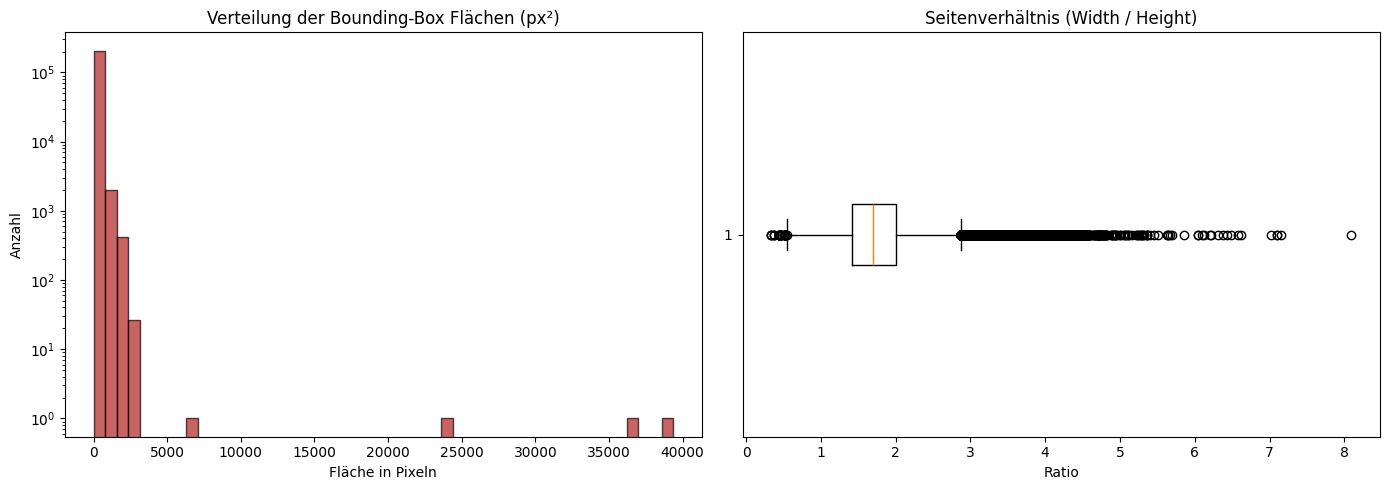

 5. SPATIAL OBJECT DISTRIBUTION (Heatmap)


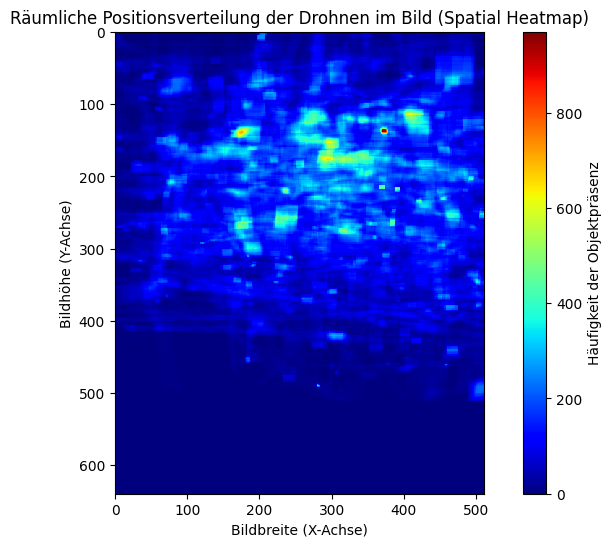

In [20]:
# ---------------------------------------------------------
# Hauptaufruf aller Analysen
# ---------------------------------------------------------
if __name__ == "__main__":
    #without_text = "01_1667_0001-1500"with_text    = "20190925_130434_1_4"
    find_text_in_seq(DATASET_DIR)
    analyze_dataset_structure(DATASET_DIR)
    analyze_bounding_boxes(DATASET_DIR)
    analyze_spatial_distribution(DATASET_DIR)